In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import generic_filter
from pathlib import Path

In [2]:
image_folder = Path(
    r"C:\Users\devah\Documents\ICT MU\Sem 5\DSIP\Lab\Images\OPE 5"
)

image_paths = [
    image_folder / "1.jpeg",
    image_folder / "2.jpeg",
    image_folder / "3.jpeg",
    image_folder / "4.jpeg"
]

images = {}

for i, path in enumerate(image_paths, start=1):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise FileNotFoundError(f"Image not found: {path}")

    images[f"Image {i}"] = image

print("All four images loaded successfully!")

All four images loaded successfully!


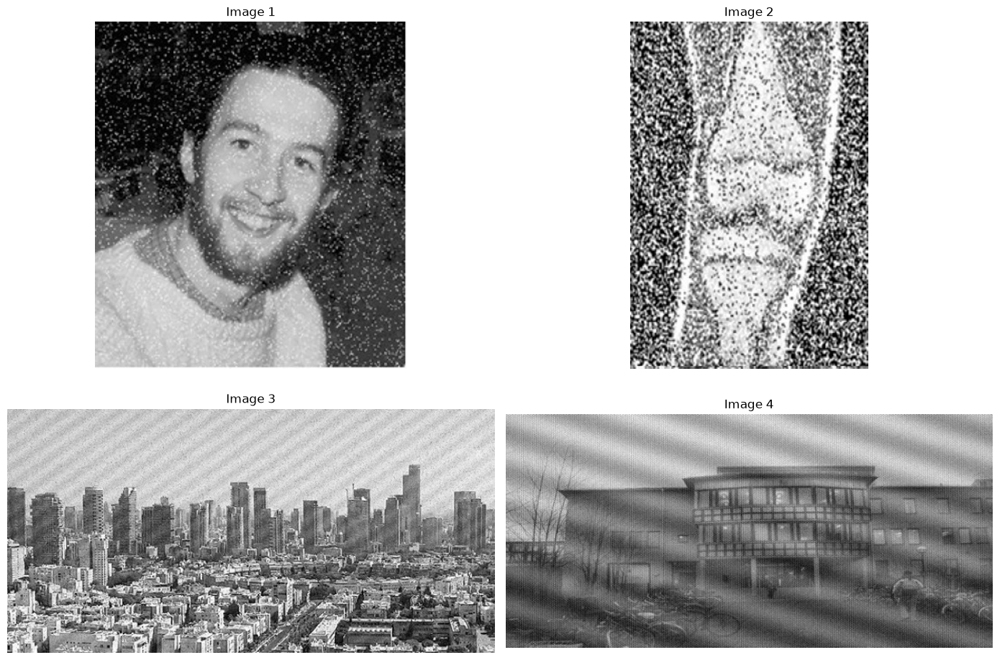

In [3]:
plt.figure(figsize=(14, 10))

for i, (name, image) in enumerate(images.items()):
    plt.subplot(2, 2, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
for name, image in images.items():
    print(name)
    print("Dimensions:", image.shape)
    print("Minimum Intensity:", np.min(image))
    print("Maximum Intensity:", np.max(image))
    print("Mean Intensity:", np.mean(image))
    print("--------------------------------")

Image 1
Dimensions: (385, 346)
Minimum Intensity: 0
Maximum Intensity: 255
Mean Intensity: 104.72517078297425
--------------------------------
Image 2
Dimensions: (388, 266)
Minimum Intensity: 0
Maximum Intensity: 255
Mean Intensity: 154.38366211921556
--------------------------------
Image 3
Dimensions: (314, 627)
Minimum Intensity: 0
Maximum Intensity: 255
Mean Intensity: 155.08094352847957
--------------------------------
Image 4
Dimensions: (303, 633)
Minimum Intensity: 37
Maximum Intensity: 219
Mean Intensity: 122.94210605894713
--------------------------------


In [5]:
def apply_median_filter(image, kernel_size):
    return cv2.medianBlur(image, kernel_size)

In [6]:
median_3 = {}

for name, image in images.items():
    median_3[name] = apply_median_filter(image, 3)

print("3x3 Median Filtering Completed!")

3x3 Median Filtering Completed!


In [7]:
median_5 = {}

for name, image in images.items():
    median_5[name] = apply_median_filter(image, 5)

print("5x5 Median Filtering Completed!")

5x5 Median Filtering Completed!


In [8]:
median_7 = {}

for name, image in images.items():
    median_7[name] = apply_median_filter(image, 7)

print("7x7 Median Filtering Completed!")

7x7 Median Filtering Completed!


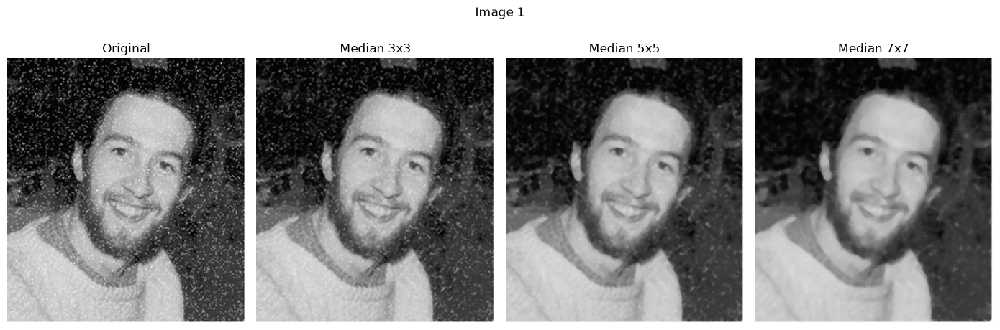

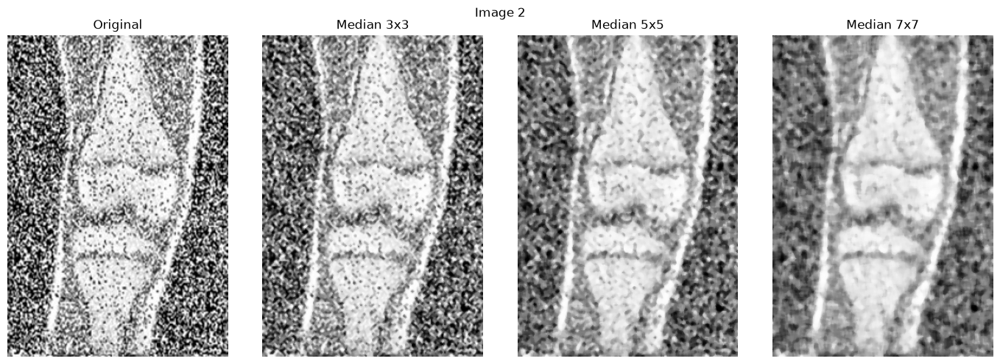

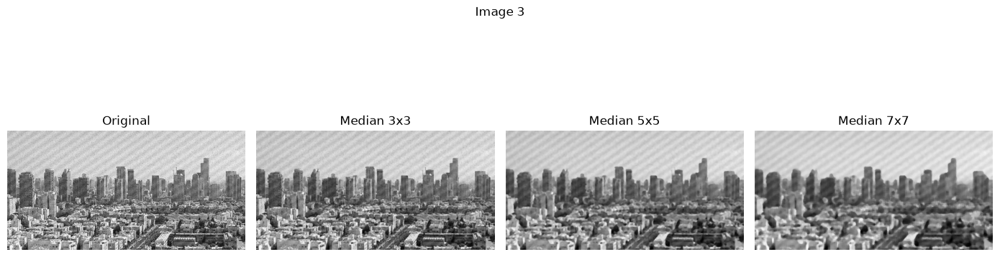

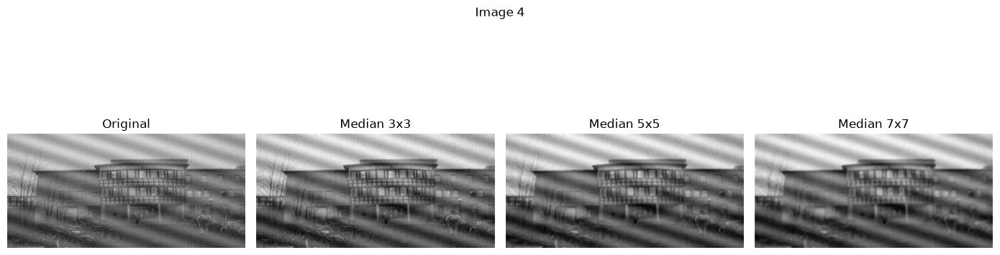

In [9]:
for name in images:

    plt.figure(figsize=(14, 5))

    results = [
        images[name],
        median_3[name],
        median_5[name],
        median_7[name]
    ]

    titles = [
        "Original",
        "Median 3x3",
        "Median 5x5",
        "Median 7x7"
    ]

    for i in range(4):
        plt.subplot(1, 4, i + 1)
        plt.imshow(results[i], cmap="gray")
        plt.title(titles[i])
        plt.axis("off")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

In [10]:
def alpha_trimmed_filter(image, kernel_size=5, d=4):

    if d >= kernel_size * kernel_size:
        raise ValueError("d must be smaller than the total window size.")

    def trimmed_mean(values):
        sorted_values = np.sort(values)

        trimmed_values = sorted_values[
            d // 2 : len(sorted_values) - d // 2
        ]

        return np.mean(trimmed_values)

    result = generic_filter(
        image.astype(np.float64),
        trimmed_mean,
        size=kernel_size,
        mode="reflect"
    )

    return np.clip(result, 0, 255).astype(np.uint8)

In [11]:
alpha_filtered = {}

for name, image in images.items():

    alpha_filtered[name] = alpha_trimmed_filter(
        image,
        kernel_size=5,
        d=4
    )

print("Alpha-Trimmed Mean Filtering Completed!")

Alpha-Trimmed Mean Filtering Completed!


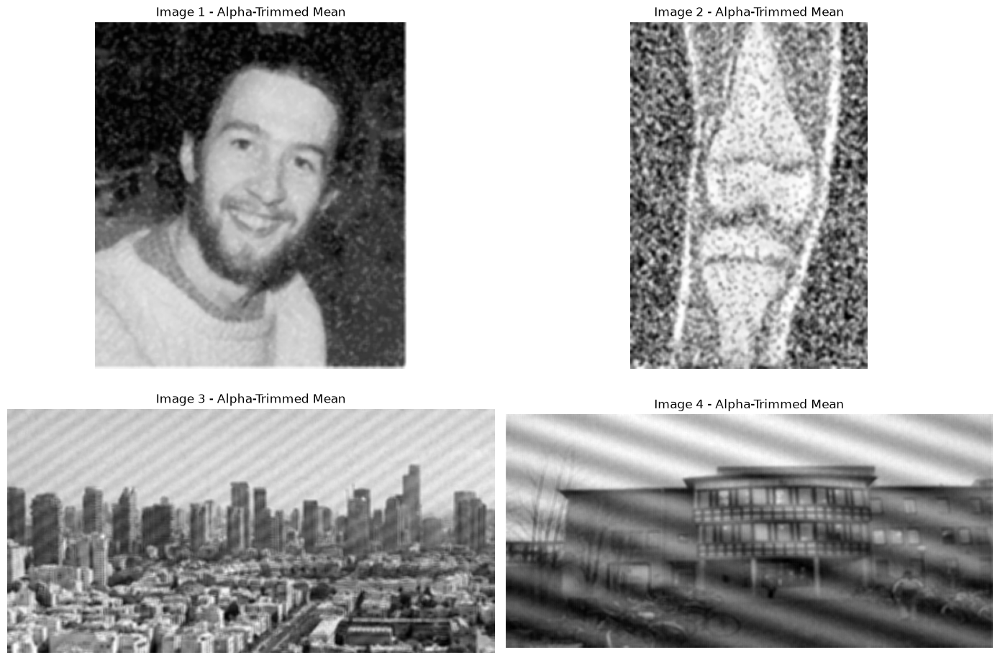

In [12]:
plt.figure(figsize=(14, 10))

for i, (name, image) in enumerate(alpha_filtered.items()):
    plt.subplot(2, 2, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(name + " - Alpha-Trimmed Mean")
    plt.axis("off")

plt.tight_layout()
plt.show()

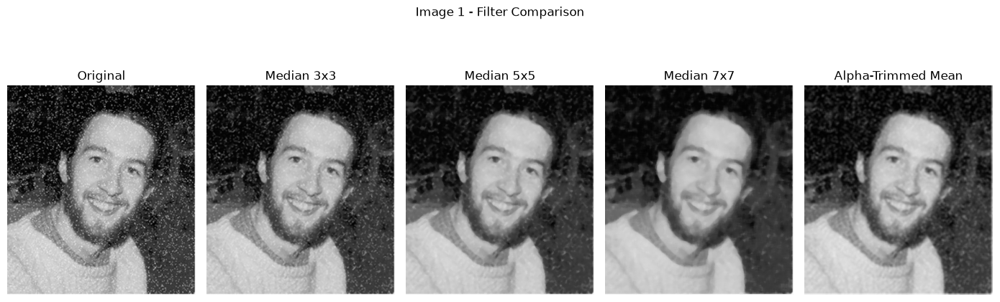

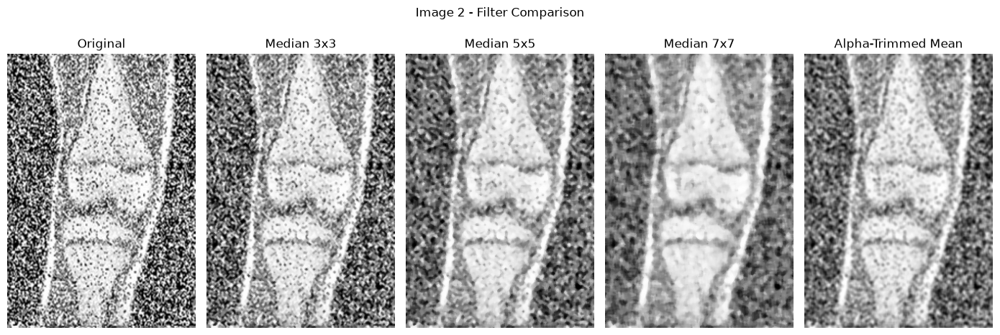

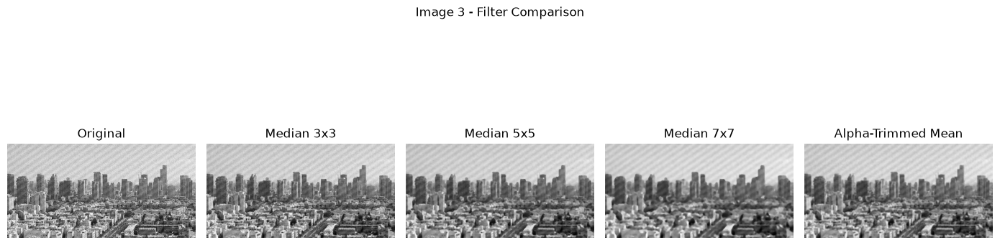

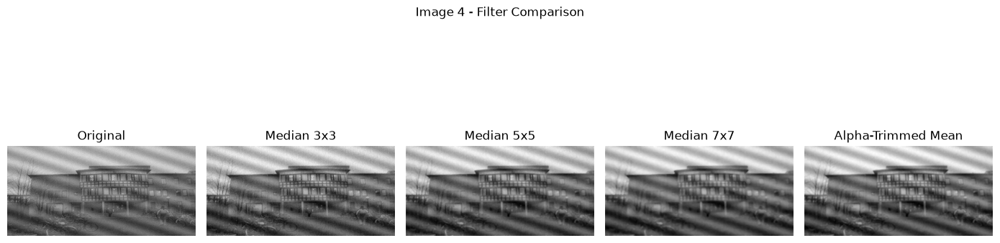

In [13]:
for name in images:

    plt.figure(figsize=(14, 5))

    results = [
        images[name],
        median_3[name],
        median_5[name],
        median_7[name],
        alpha_filtered[name]
    ]

    titles = [
        "Original",
        "Median 3x3",
        "Median 5x5",
        "Median 7x7",
        "Alpha-Trimmed Mean"
    ]

    for i in range(5):
        plt.subplot(1, 5, i + 1)
        plt.imshow(results[i], cmap="gray")
        plt.title(titles[i])
        plt.axis("off")

    plt.suptitle(name + " - Filter Comparison")
    plt.tight_layout()
    plt.show()

In [14]:
def get_edge_image(image):
    sobel_x = cv2.Sobel(
        image, cv2.CV_64F, 1, 0, ksize=3
    )

    sobel_y = cv2.Sobel(
        image, cv2.CV_64F, 0, 1, ksize=3
    )

    magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

    return np.uint8(
        np.clip(magnitude, 0, 255)
    )

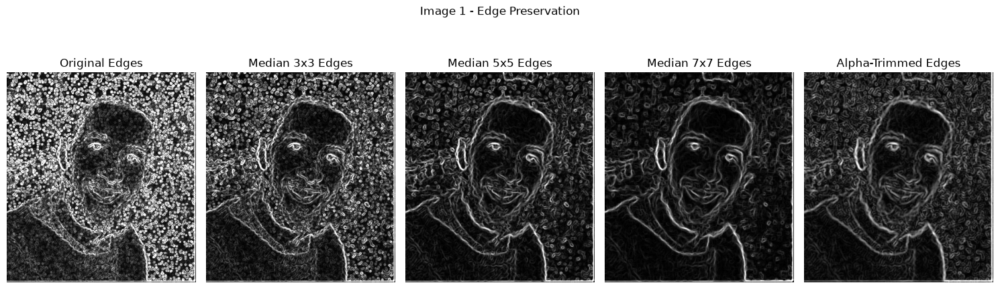

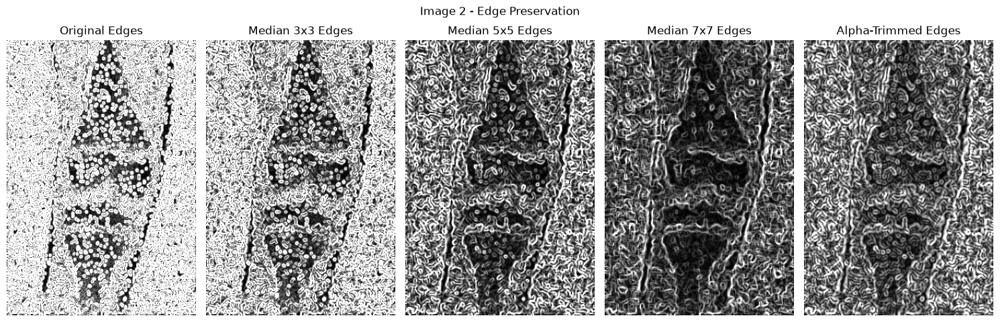

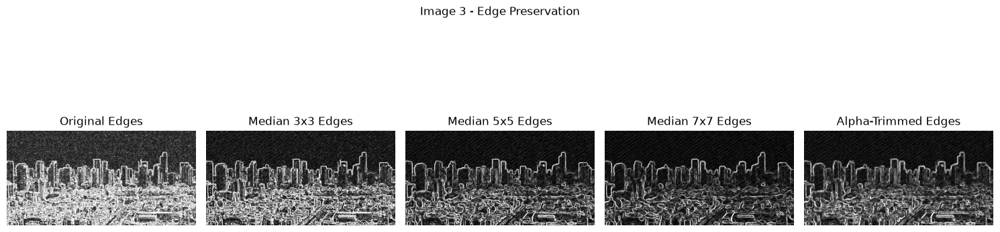

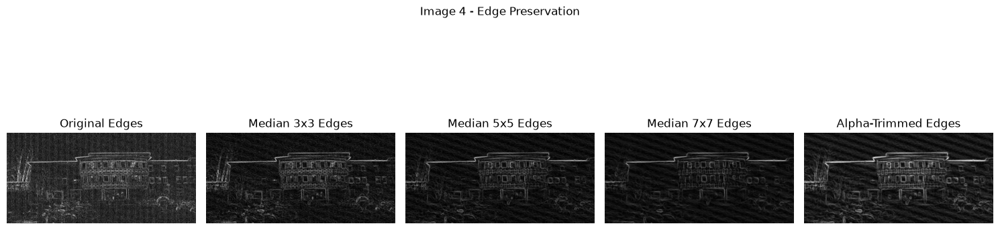

In [15]:
for name in images:

    results = [
        images[name],
        median_3[name],
        median_5[name],
        median_7[name],
        alpha_filtered[name]
    ]

    titles = [
        "Original Edges",
        "Median 3x3 Edges",
        "Median 5x5 Edges",
        "Median 7x7 Edges",
        "Alpha-Trimmed Edges"
    ]

    plt.figure(figsize=(15, 5))

    for i, result in enumerate(results):
        plt.subplot(1, 5, i + 1)
        plt.imshow(get_edge_image(result), cmap="gray")
        plt.title(titles[i])
        plt.axis("off")

    plt.suptitle(name + " - Edge Preservation")
    plt.tight_layout()
    plt.show()

In [16]:
for name in images:

    print("\n", name)
    print("-" * 45)

    results = {
        "Original": images[name],
        "Median 3x3": median_3[name],
        "Median 5x5": median_5[name],
        "Median 7x7": median_7[name],
        "Alpha-Trimmed": alpha_filtered[name]
    }

    for filter_name, result in results.items():

        print(filter_name)
        print("Mean:", round(np.mean(result), 2))
        print("Standard Deviation:", round(np.std(result), 2))
        print()


 Image 1
---------------------------------------------
Original
Mean: 104.73
Standard Deviation: 73.94

Median 3x3
Mean: 102.96
Standard Deviation: 73.56

Median 5x5
Mean: 101.74
Standard Deviation: 73.68

Median 7x7
Mean: 101.34
Standard Deviation: 73.85

Alpha-Trimmed
Mean: 103.03
Standard Deviation: 71.72


 Image 2
---------------------------------------------
Original
Mean: 154.38
Standard Deviation: 71.11

Median 3x3
Mean: 155.02
Standard Deviation: 65.51

Median 5x5
Mean: 156.01
Standard Deviation: 59.83

Median 7x7
Mean: 156.94
Standard Deviation: 56.29

Alpha-Trimmed
Mean: 154.49
Standard Deviation: 55.73


 Image 3
---------------------------------------------
Original
Mean: 155.08
Standard Deviation: 57.35

Median 3x3
Mean: 155.27
Standard Deviation: 53.66

Median 5x5
Mean: 155.0
Standard Deviation: 51.64

Median 7x7
Mean: 154.58
Standard Deviation: 50.49

Alpha-Trimmed
Mean: 154.63
Standard Deviation: 50.14


 Image 4
---------------------------------------------
Original


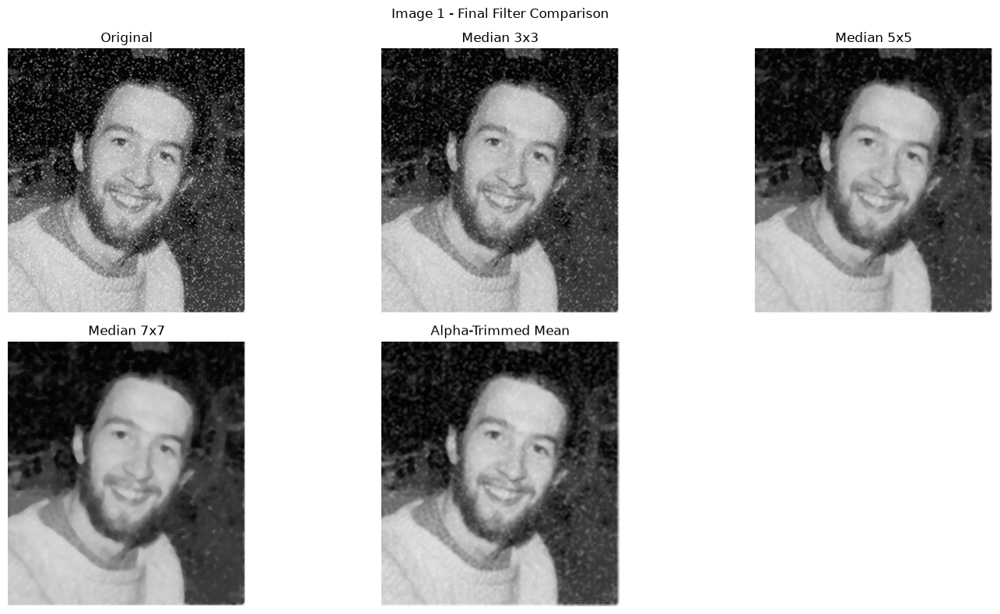

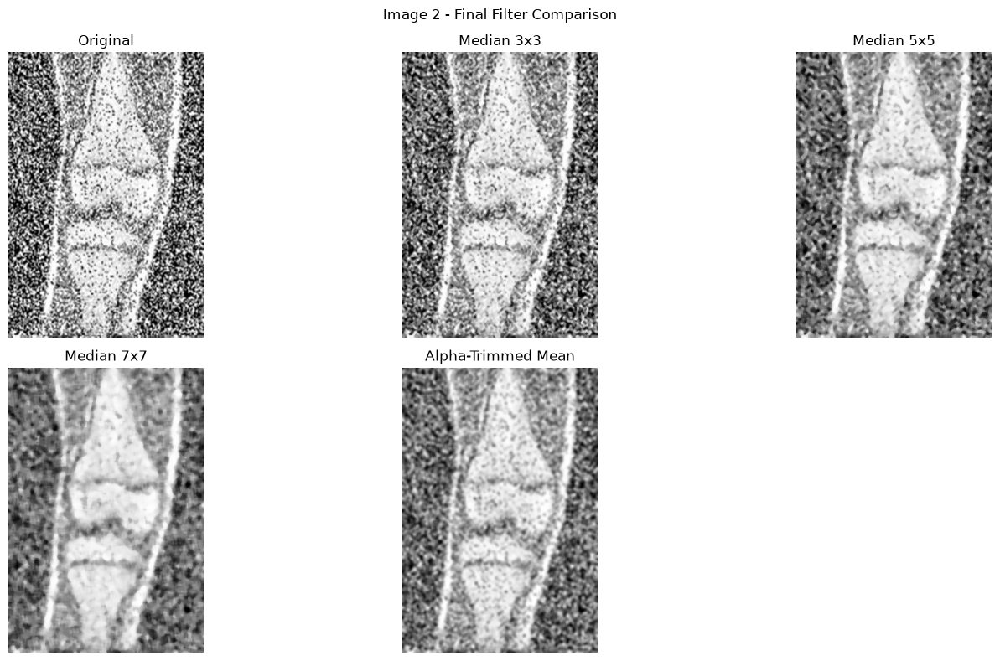

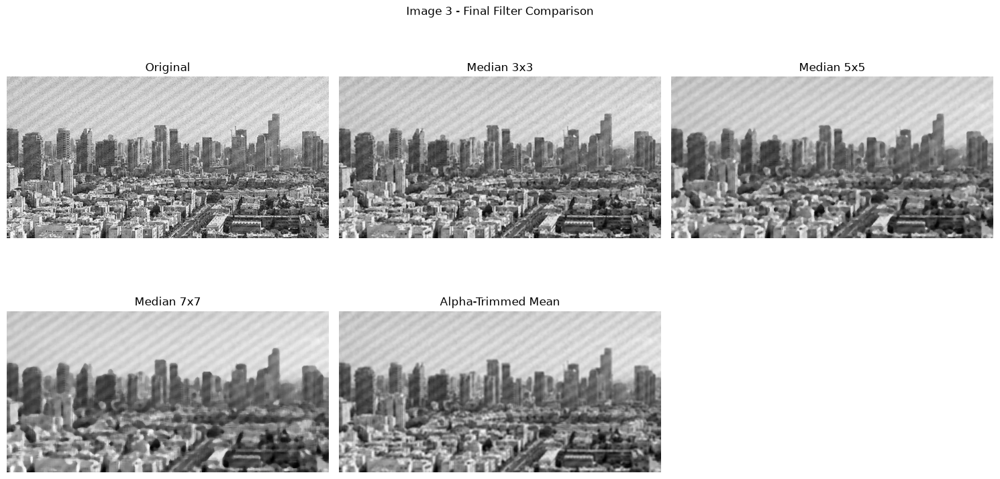

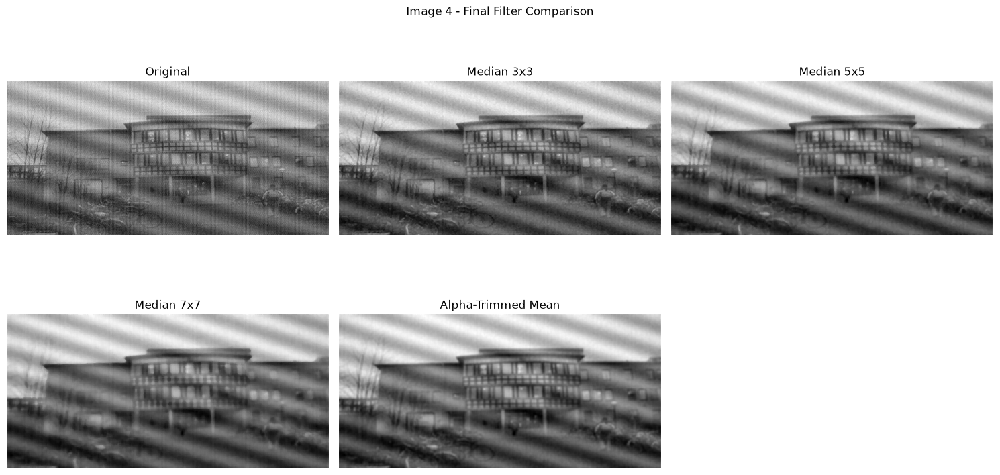

In [17]:
for name in images:

    plt.figure(figsize=(15, 8))

    results = [
        images[name],
        median_3[name],
        median_5[name],
        median_7[name],
        alpha_filtered[name]
    ]

    titles = [
        "Original",
        "Median 3x3",
        "Median 5x5",
        "Median 7x7",
        "Alpha-Trimmed Mean"
    ]

    for i, result in enumerate(results):
        plt.subplot(2, 3, i + 1)
        plt.imshow(result, cmap="gray")
        plt.title(titles[i])
        plt.axis("off")

    plt.suptitle(name + " - Final Filter Comparison")
    plt.tight_layout()
    plt.show()

In [18]:
output_folder = image_folder / "Filtered_Results"
output_folder.mkdir(exist_ok=True)

for name in images:

    results = {
        "Median_3x3": median_3[name],
        "Median_5x5": median_5[name],
        "Median_7x7": median_7[name],
        "Alpha_Trimmed": alpha_filtered[name]
    }

    for filter_name, result in results.items():

        filename = f"{name.replace(' ', '_')}_{filter_name}.png"

        cv2.imwrite(
            str(output_folder / filename),
            result
        )

print("All filtered images saved successfully!")
print("Output Location:", output_folder)

All filtered images saved successfully!
Output Location: C:\Users\devah\Documents\ICT MU\Sem 5\DSIP\Lab\Images\OPE 5\Filtered_Results
